In [9]:
import pandas as pd
data = pd.read_excel('/Users/bibhasvata/Downloads/Work/CN/Plant Bulk Isotope Composition.xlsx', sheet_name='Sheet1')
data.columns

Index(['ID', 'Transect', 'Species', 'Genus', 'Mycorrhizal association',
       'Domain', 'Latitude', 'Longitude', 'Elevation (m)',
       'Precipitation MAM (mm/m)', 'Surface Temperature JJA (K)',
       'Soil Moisture (m3/m3)', 'Soil Temperature (K)',
       'Precipitation Annual (mm/m)', 'Surface Temperature Annual (K)',
       'δ15N (‰)', 'TN (%)', 'δ13C (‰)', 'TOC (%)', 'C/N'],
      dtype='object')

/Users/bibhasvata/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/var/folders/38/3pgct8wj0n91tc37dqk7w1ph0000gn/T/ipykernel_5507/2933672253.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Cluster'] = kmeans.fit_predict(X_scaled)


Silhouette Score: 0.5253859235435496
Adjusted Rand Index: 0.12658179931199715


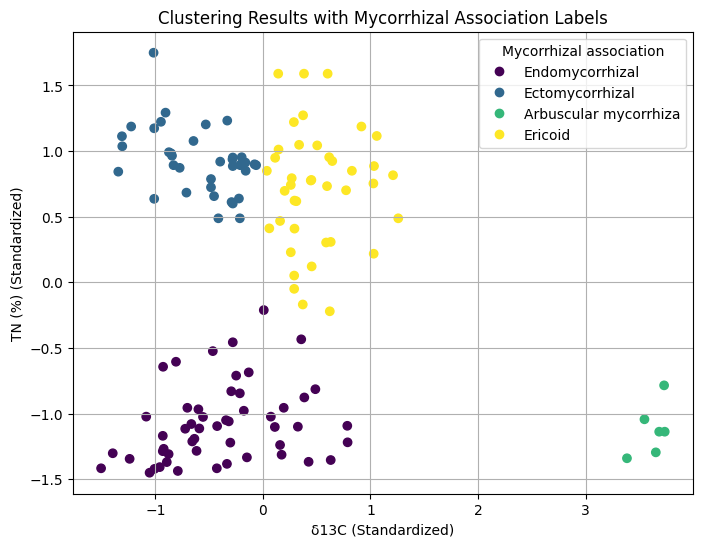

In [37]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
import matplotlib.pyplot as plt

# selecting rows based on condition
options = ['Endomycorrhizal', 'Ectomycorrhizal', 'Arbuscular mycorrhiza', 'Ericoid']
df_filtered = data.loc[data['Mycorrhizal association'].isin(options)]

# Extract the relevant columns
X = df_filtered[['δ13C (‰)', 'TN (%)']]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Chosen optimal number of clusters (k)
optimal_k = 4

# Perform clustering
kmeans = KMeans(n_clusters=optimal_k, random_state=0)
df_filtered['Cluster'] = kmeans.fit_predict(X_scaled)

# Evaluate clustering using Silhouette Score
silhouette_avg = silhouette_score(X_scaled, df_filtered['Cluster'])
print(f'Silhouette Score: {silhouette_avg}')

# Evaluate clustering against 'Mycorrhizal association' using Adjusted Rand Index
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
true_labels = label_encoder.fit_transform(df_filtered['Mycorrhizal association'])

adjusted_rand = adjusted_rand_score(true_labels, df_filtered['Cluster'])
print(f'Adjusted Rand Index: {adjusted_rand}')

# Visualize the clusters and label 'Mycorrhizal association'
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=df_filtered['Cluster'], cmap='viridis')

plt.xlabel('δ13C (Standardized)')
plt.ylabel('TN (%) (Standardized)')
plt.title('Clustering Results with Mycorrhizal Association Labels')
plt.grid()

# Create a legend for cluster colors
handles, labels = scatter.legend_elements()
plt.legend(handles, options, title='Mycorrhizal association')
plt.show()


In [28]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
import matplotlib.pyplot as plt
from itertools import combinations


# selecting rows based on condition
options = ['Gymnosperm', 'Angiosperm', 'Grass C3', 'Grass C4']
df = data.loc[data['Domain'].isin(options)]

# Define the features you want to consider in combinations
feature_columns = ["TOC (%)", "δ13C (‰)", "TN (%)", "δ15N (‰)", "C/N"]

# Initialize lists to store the results
results = []

# Generate dual feature combinations
for comb in combinations(feature_columns, 2):
    # Extract the relevant columns for this combination
    X = df[list(comb)]

    # Standardize the features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Chosen optimal number of clusters (k)
    optimal_k = 4

    # Perform clustering
    kmeans = KMeans(n_clusters=optimal_k, random_state=0)
    df['Cluster'] = kmeans.fit_predict(X_scaled)

    # Evaluate clustering using Silhouette Score
    silhouette_avg = silhouette_score(X_scaled, df['Cluster'])

    # Evaluate clustering against 'Mycorrhizal association' using Adjusted Rand Index
    from sklearn.preprocessing import LabelEncoder
    label_encoder = LabelEncoder()
    true_labels = label_encoder.fit_transform(df['Mycorrhizal association'])
    adjusted_rand = adjusted_rand_score(true_labels, df['Cluster'])

    # Append the results to the list
    results.append({
        'Features': ', '.join(comb),
        'Silhouette Score': silhouette_avg,
        'Adjusted Rand Index': adjusted_rand
    })

# Create an output DataFrame and display it
output_df = pd.DataFrame(results)
print(output_df)


/Users/bibhasvata/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/var/folders/38/3pgct8wj0n91tc37dqk7w1ph0000gn/T/ipykernel_5507/632132082.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Cluster'] = kmeans.fit_predict(X_scaled)
/Users/bibhasvata/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/var/folders/38/3pgct8wj0n91tc37dqk7w1ph0000gn/T/ipykernel_5507/632132082.

             Features  Silhouette Score  Adjusted Rand Index
0   TOC (%), δ13C (‰)          0.380086             0.073978
1     TOC (%), TN (%)          0.436856             0.085327
2   TOC (%), δ15N (‰)          0.401879             0.080544
3        TOC (%), C/N          0.379740             0.019067
4    δ13C (‰), TN (%)          0.525386             0.126582
5  δ13C (‰), δ15N (‰)          0.428601             0.108657
6       δ13C (‰), C/N          0.469618             0.122894
7    TN (%), δ15N (‰)          0.409863             0.048928
8         TN (%), C/N          0.674936             0.072348
9       δ15N (‰), C/N          0.509356             0.031700


/Users/bibhasvata/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/var/folders/38/3pgct8wj0n91tc37dqk7w1ph0000gn/T/ipykernel_5507/632132082.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Cluster'] = kmeans.fit_predict(X_scaled)
/Users/bibhasvata/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/var/folders/38/3pgct8wj0n91tc37dqk7w1ph0000gn/T/ipykernel_5507/632132082.

In [32]:
output_df.to_csv('Cluster.csv')

In [ ]:
"""
Python code to generate manuscript figures (Fig 1b, 1c, Fig 2, Fig 3a-d)
Based on rerun TN% data for C&N Allocation Manuscript

Outputs:
    - Fig1b_d13C_TOC_by_transect.png
    - Fig1c_d15N_TN_by_transect.png
    - Fig2_mycorrhizal_clustering.png
    - Fig3_isoscape_validation.png
"""

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 10

# ============================================================================
# PATHS
# ============================================================================

PROJECT_DIR = Path(
    "/Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht(2)/PostDoc/Projects/CN"
)

FULL_DATA_PATH = PROJECT_DIR / "Plant Bulk Isotope Composition.xlsx"
RERUN_TN_PATH = PROJECT_DIR / "CN Manuscript" / "TN_Rerun_Comparison.xlsx"
OUTPUT_DIR = PROJECT_DIR / "CN Manuscript" / "Figure_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================================
# LOAD AND PREPARE DATA
# ============================================================================

df = pd.read_excel(FULL_DATA_PATH, sheet_name="Sheet1")
tn_rerun = pd.read_excel(RERUN_TN_PATH)

# Merge rerun TN values into the full isotope dataset.
# ID is the matching key between these two files; transect labels differ.
tn_cols = ["ID", "TN%_Corrected", "TN%_Rerun"]
df = df.merge(tn_rerun[tn_cols], on="ID", how="left", suffixes=("", "_rerun_file"))

# Clean aliases used throughout the plotting code.
df["d13C"] = df["δ13C (‰)"]
df["d15N"] = df["δ15N (‰)"]
df["TOC_%"] = df["TOC (%)"]

# Prefer rerun TN values where available, then corrected TN, then original TN.
df["TN%_Final"] = df["TN%_Rerun"].fillna(df["TN%_Corrected"]).fillna(df["TN (%)"])

# Normalize genus names for plotting.
def normalize_genus(row):
    genus = row.get("Genus")
    species = row.get("Species")

    if pd.notna(genus):
        genus_str = str(genus)
        if genus_str.startswith("Grass"):
            return "Grass"
        return genus_str

    if pd.isna(species):
        return "Unknown"

    species_str = str(species)
    for name in ["Rhododendron", "Pinus", "Abies", "Juniperus", "Grass", "Dung"]:
        if name in species_str:
            return name

    return "Unidentified"

df["Genus"] = df.apply(normalize_genus, axis=1)

genus_colors = {
    "Rhododendron": "#3B7EA1",
    "Pinus": "#FDB462",
    "Abies": "#8FBC8F",
    "Juniperus": "#B03060",
    "Grass": "#808080",
    "Dung": "#A52A2A",
    "Unidentified": "#D3D3D3",
    "Unknown": "#D3D3D3",
}

transects = [
    "Western Himalaya (Karnali)",
    "Central Himalaya (Annapurna)",
    "Eastern Himalaya (Kosi)",
]
x_positions = np.arange(len(transects))
width = 0.15
genera_to_plot = ["Rhododendron", "Pinus", "Abies", "Juniperus"]

legend_elements = [
    Patch(facecolor=genus_colors[g], edgecolor="black", label=g, alpha=0.7)
    for g in genera_to_plot
]

def plot_violin_or_point(ax, values, position, color, width):
    values = pd.Series(values).dropna()

    if len(values) == 0:
        return

    if len(values) >= 2:
        parts = ax.violinplot(
            [values],
            positions=[position],
            widths=width * 0.9,
            showmeans=False,
            showextrema=False,
        )
        for pc in parts["bodies"]:
            pc.set_facecolor(color)
            pc.set_alpha(0.7)
            pc.set_edgecolor("black")
            pc.set_linewidth(0.5)
    else:
        ax.scatter(
            [position],
            values,
            s=45,
            color=color,
            alpha=0.8,
            edgecolor="black",
            linewidth=0.5,
            zorder=3,
        )

def r_squared(x, y):
    x = np.asarray(x)
    y = np.asarray(y)
    if len(x) < 2:
        return np.nan, np.nan
    r = np.corrcoef(x, y)[0, 1]
    return r, r**2

# ============================================================================
# FIGURE 1B: δ13C AND TOC BY TRANSECT
# ============================================================================

print("Generating Figure 1b: δ13C and TOC by transect...")

fig1b, ax1 = plt.subplots(1, 1, figsize=(12, 6))

for i, transect in enumerate(transects):
    for j, genus in enumerate(genera_to_plot):
        subset = df[(df["Transect"] == transect) & (df["Genus"] == genus)]
        position = x_positions[i] - 0.3 + j * width
        plot_violin_or_point(ax1, subset["d13C"], position, genus_colors[genus], width)

ax2 = ax1.twinx()

for i, transect in enumerate(transects):
    for j, genus in enumerate(genera_to_plot):
        subset = df[(df["Transect"] == transect) & (df["Genus"] == genus)]
        if len(subset) > 0:
            position = x_positions[i] - 0.3 + j * width
            mean_toc = subset["TOC_%"].mean()
            ax2.bar(
                position,
                mean_toc,
                width=width * 0.8,
                alpha=0.3,
                color=genus_colors[genus],
                edgecolor="black",
                linewidth=0.5,
            )

ax1.set_ylabel("δ¹³C (‰, VPDB)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Transect", fontsize=12, fontweight="bold")
ax1.set_xticks(x_positions)
ax1.set_xticklabels(transects)
ax1.set_ylim(-34, -18)
#ax1.axhline(y=-24.5, color="gray", linestyle="--", linewidth=0.5, alpha=0.5)

ax2.set_ylabel("Mean TOC (%)", fontsize=12, fontweight="bold")
ax2.set_ylim(0, 200)

ax1.legend(
    handles=legend_elements,
    loc="upper left",
    frameon=True,
    title="Genus",
    fontsize=9,
)

plt.title(
    "Distribution of δ¹³C values and TOC across the three transects",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Fig1b_d13C_TOC_by_transect.png", dpi=300, bbox_inches="tight")
plt.close()
print("Saved Fig1b_d13C_TOC_by_transect.png")

# ============================================================================
# FIGURE 1C: δ15N AND TN BY TRANSECT
# ============================================================================

print("\nGenerating Figure 1c: δ15N and TN by transect...")

fig1c, ax1 = plt.subplots(1, 1, figsize=(12, 6))

for i, transect in enumerate(transects):
    for j, genus in enumerate(genera_to_plot):
        subset = df[(df["Transect"] == transect) & (df["Genus"] == genus)]
        position = x_positions[i] - 0.3 + j * width
        plot_violin_or_point(ax1, subset["d15N"], position, genus_colors[genus], width)

ax2 = ax1.twinx()

for i, transect in enumerate(transects):
    for j, genus in enumerate(genera_to_plot):
        subset = df[(df["Transect"] == transect) & (df["Genus"] == genus)]
        if len(subset) > 0:
            position = x_positions[i] - 0.3 + j * width
            mean_tn = subset["TN%_Final"].mean()
            ax2.bar(
                position,
                mean_tn,
                width=width * 0.8,
                alpha=0.3,
                color=genus_colors[genus],
                edgecolor="black",
                linewidth=0.5,
            )

ax1.set_ylabel("δ¹⁵N (‰, AIR)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Transect", fontsize=12, fontweight="bold")
ax1.set_xticks(x_positions)
ax1.set_xticklabels(transects)
ax1.set_ylim(-5, 15)
#ax1.axhline(y=0, color="gray", linestyle="--", linewidth=0.5, alpha=0.5)

ax2.set_ylabel("Mean TN (%)", fontsize=12, fontweight="bold")
ax2.set_ylim(0, 40)

ax1.legend(
    handles=legend_elements,
    loc="upper left",
    frameon=True,
    title="Genus",
    fontsize=9,
)

plt.title(
    "Distribution of δ¹⁵N values and TN across the three transects",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Fig1c_d15N_TN_by_transect.png", dpi=300, bbox_inches="tight")
plt.close()
print("Saved Fig1c_d15N_TN_by_transect.png")

# ============================================================================
# FIGURE 2: MYCORRHIZAL CLUSTERING
# ============================================================================

print("\nGenerating Figure 2: Mycorrhizal clustering...")

mycorrhizal_type = {
    "Rhododendron": "Ericoid",
    "Pinus": "Ectomycorrhizal",
    "Abies": "Ectomycorrhizal",
    "Juniperus": "Endomycorrhizal",
    "Grass": "Arbuscular mycorrhiza",
    "Dung": "Endomycorrhizal",
    "Unidentified": "Endomycorrhizal",
    "Unknown": "Endomycorrhizal",
}

df["Mycorrhizal"] = df["Genus"].map(mycorrhizal_type)
df["Mycorrhizal"] = df["Mycorrhizal"].fillna(df["Mycorrhizal association"])

df_clean = df[["d13C", "TN%_Final", "Mycorrhizal"]].dropna().copy()

scaler = StandardScaler()
df_clean[["d13C_std", "TN_std"]] = scaler.fit_transform(
    df_clean[["d13C", "TN%_Final"]]
)

myco_colors = {
    "Endomycorrhizal": "#1f77b4",
    "Ectomycorrhizal": "#2ca02c",
    "Arbuscular mycorrhiza": "#17becf",
    "Ericoid": "#ffbb00",
}

fig2, ax = plt.subplots(1, 1, figsize=(10, 8))

for myco_type in myco_colors:
    subset = df_clean[df_clean["Mycorrhizal"] == myco_type]
    if len(subset) == 0:
        continue

    ax.scatter(
        subset["d13C_std"],
        subset["TN_std"],
        c=myco_colors[myco_type],
        label=myco_type,
        s=80,
        alpha=0.7,
        edgecolors="black",
        linewidth=0.5,
    )

ax.set_xlabel("δ¹³C (Standardized)", fontsize=13, fontweight="bold")
ax.set_ylabel("TN (%) (Standardized)", fontsize=13, fontweight="bold")
ax.set_title(
    "Mycorrhizae-Genera clustering results with Mycorrhizal Association Labels",
    fontsize=13,
    fontweight="bold",
)
ax.legend(
    title="Mycorrhizal association",
    fontsize=10,
    title_fontsize=11,
    loc="upper right",
    frameon=True,
    edgecolor="black",
)
#ax.grid(True, alpha=0.3)
ax.axhline(y=0, color="gray", linestyle="-", linewidth=0.5, alpha=0.5)
ax.axvline(x=0, color="gray", linestyle="-", linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Fig2_mycorrhizal_clustering.png", dpi=300, bbox_inches="tight")
plt.close()
print("Saved Fig2_mycorrhizal_clustering.png")

# ============================================================================
# FIGURE 3A-D: ISOSCAPE VALIDATION USING MODEL EQUATIONS
# ============================================================================

print("\nGenerating Figure 3a-d: Isoscape validation plots...")

# Model driver aliases
df_model = df.copy()

df_model["GST_K"] = df_model["Surface Temperature Annual (K)"]
df_model["GSP_mm"] = df_model["Precipitation Annual (mm/m)"]
df_model["Elevation_m"] = df_model["Elevation (m)"]
df_model["SMN_gN_m2"] = df_model["Soil Microbial Niotrogen (gN/m2)"]

# Model equation uses SM in kg/m3; source file has volumetric m3/m3.
# Convert assuming water density ~1000 kg/m3.
df_model["SM_kg_m3"] = df_model["Soil Moisture (m3/m3)"] * 1000

# C3/C4 dummy variable:
# C4 = 1, C3/non-C4 = 0.
# If your published equation instead means +1 for C4 and -1 for C3,
# change the last line to: np.where(df_model["Domain"].eq("Grass C4"), 1, -1)
df_model["C4_dummy"] = np.where(df_model["Domain"].eq("Grass C4"), 1, 0)

# Observed isotope aliases, if not already created earlier
df_model["d13C"] = df_model["δ13C (‰)"]
df_model["d15N"] = df_model["δ15N (‰)"]

# Modelled values from manuscript equations
df_model["d13C_modelled"] = (
    -210.97
    + 0.16 * df_model["GST_K"]
    - 0.0003 * df_model["GSP_mm"]
    - 0.001 * df_model["Elevation_m"]
    + 1.29 * df_model["SMN_gN_m2"]
    + 6.27 * df_model["C4_dummy"]
)

df_model["d15N_modelled"] = (
    133.46
    + 0.12 * df_model["GST_K"]
    - 0.19 * df_model["GSP_mm"]
    - 0.006 * df_model["SM_kg_m3"]
    - 1.41 * df_model["SMN_gN_m2"]
)

# Keep only complete rows
df_plot = df_model[
    [
        "Transect",
        "d15N",
        "d13C",
        "d15N_modelled",
        "d13C_modelled",
    ]
].dropna().copy()

# Residuals: observed - modelled
df_plot["d15N_residual"] = df_plot["d15N"] - df_plot["d15N_modelled"]
df_plot["d13C_residual"] = df_plot["d13C"] - df_plot["d13C_modelled"]

def model_stats(obs, pred):
    obs = np.asarray(obs)
    pred = np.asarray(pred)
    r = np.corrcoef(obs, pred)[0, 1]
    r2 = r**2
    rmse = np.sqrt(np.mean((obs - pred) ** 2))
    mae = np.mean(np.abs(obs - pred))
    return r, r2, rmse, mae

fig3, axes = plt.subplots(2, 2, figsize=(14, 12))

transect_colors = {
    "Central Himalaya (Annapurna)": "#4169E1",
    "Western Himalaya (Karnali)": "#32CD32",
    "Eastern Himalaya (Kosi)": "#DC143C",
}

transect_labels = {
    "Central Himalaya (Annapurna)": "AP",
    "Western Himalaya (Karnali)": "K",
    "Eastern Himalaya (Kosi)": "DKB",
}

# -------------------- 3a: d15N observed vs modelled --------------------
ax = axes[0, 0]

for transect, color in transect_colors.items():
    subset = df_plot[df_plot["Transect"] == transect]
    ax.scatter(
        subset["d15N"],
        subset["d15N_modelled"],
        c=color,
        label=transect_labels[transect],
        s=60,
        alpha=0.6,
        edgecolors="black",
        linewidth=0.5,
    )

min_val = min(df_plot["d15N"].min(), df_plot["d15N_modelled"].min())
max_val = max(df_plot["d15N"].max(), df_plot["d15N_modelled"].max())
ax.plot([min_val, max_val], [min_val, max_val], "k--", linewidth=2, label="1:1 line")

r, r2, rmse, mae = model_stats(df_plot["d15N"], df_plot["d15N_modelled"])
ax.text(
    0.05,
    0.95,
    f"R² = {r2:.3f}\nr = {r:.3f}\nRMSE = {rmse:.2f}‰\nMAE = {mae:.2f}‰",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
)

ax.set_xlabel("Observed δ¹⁵N (‰)", fontsize=12, fontweight="bold")
ax.set_ylabel("Modelled δ¹⁵N (‰)", fontsize=12, fontweight="bold")
ax.set_title("(a) δ¹⁵N: Observed vs Modelled", fontsize=12, fontweight="bold")
ax.legend(title="Transect", fontsize=9)
ax.grid(True, alpha=0.3)

# -------------------- 3b: d13C observed vs modelled --------------------
ax = axes[0, 1]

for transect, color in transect_colors.items():
    subset = df_plot[df_plot["Transect"] == transect]
    ax.scatter(
        subset["d13C"],
        subset["d13C_modelled"],
        c=color,
        label=transect_labels[transect],
        s=60,
        alpha=0.6,
        edgecolors="black",
        linewidth=0.5,
    )

min_val = min(df_plot["d13C"].min(), df_plot["d13C_modelled"].min())
max_val = max(df_plot["d13C"].max(), df_plot["d13C_modelled"].max())
ax.plot([min_val, max_val], [min_val, max_val], "k--", linewidth=2, label="1:1 line")

r, r2, rmse, mae = model_stats(df_plot["d13C"], df_plot["d13C_modelled"])
ax.text(
    0.05,
    0.95,
    f"R² = {r2:.3f}\nr = {r:.3f}\nRMSE = {rmse:.2f}‰\nMAE = {mae:.2f}‰",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
)

ax.set_xlabel("Observed δ¹³C (‰)", fontsize=12, fontweight="bold")
ax.set_ylabel("Modelled δ¹³C (‰)", fontsize=12, fontweight="bold")
ax.set_title("(b) δ¹³C: Observed vs Modelled", fontsize=12, fontweight="bold")
ax.legend(title="Transect", fontsize=9)
ax.grid(True, alpha=0.3)

# -------------------- 3c: d15N residuals histogram --------------------
ax = axes[1, 0]

for transect, color in transect_colors.items():
    subset = df_plot[df_plot["Transect"] == transect]
    ax.hist(
        subset["d15N_residual"],
        bins=15,
        alpha=0.5,
        color=color,
        label=transect_labels[transect],
        edgecolor="black",
        linewidth=0.5,
    )

ax.axvline(x=0, color="red", linestyle="--", linewidth=2)
ax.set_xlabel("Residual δ¹⁵N (observed - modelled, ‰)", fontsize=12, fontweight="bold")
ax.set_ylabel("Count", fontsize=12, fontweight="bold")
ax.set_title("(c) δ¹⁵N Model Residuals", fontsize=12, fontweight="bold")
ax.legend(title="Transect", fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

# -------------------- 3d: d13C residuals histogram --------------------
ax = axes[1, 1]

for transect, color in transect_colors.items():
    subset = df_plot[df_plot["Transect"] == transect]
    ax.hist(
        subset["d13C_residual"],
        bins=15,
        alpha=0.5,
        color=color,
        label=transect_labels[transect],
        edgecolor="black",
        linewidth=0.5,
    )

ax.axvline(x=0, color="red", linestyle="--", linewidth=2)
ax.set_xlabel("Residual δ¹³C (observed - modelled, ‰)", fontsize=12, fontweight="bold")
ax.set_ylabel("Count", fontsize=12, fontweight="bold")
ax.set_title("(d) δ¹³C Model Residuals", fontsize=12, fontweight="bold")
ax.legend(title="Transect", fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "Fig3_isoscape_validation.png",
    dpi=300,
    bbox_inches="tight",
)
plt.close()

print("Saved Fig3_isoscape_validation.png")

# ============================================================================
# SUMMARY
# ============================================================================

print("\n" + "=" * 70)
print("ALL FIGURES GENERATED SUCCESSFULLY")
print("=" * 70)
print("\nOutputs:")
print(f"  1. {OUTPUT_DIR / 'Fig1b_d13C_TOC_by_transect.png'}")
print(f"  2. {OUTPUT_DIR / 'Fig1c_d15N_TN_by_transect.png'}")
print(f"  3. {OUTPUT_DIR / 'Fig2_mycorrhizal_clustering.png'}")
print(f"  4. {OUTPUT_DIR / 'Fig3_isoscape_validation.png'}")
print("=" * 70)


Generating Figure 1b: δ13C and TOC by transect...
Saved Fig1b_d13C_TOC_by_transect.png

Generating Figure 1c: δ15N and TN by transect...
Saved Fig1c_d15N_TN_by_transect.png

Generating Figure 2: Mycorrhizal clustering...
Saved Fig2_mycorrhizal_clustering.png

Generating Figure 3a-d: Isoscape validation plots...
Saved Fig3_isoscape_validation.png

ALL FIGURES GENERATED SUCCESSFULLY

Outputs:
  1. /Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht(2)/PostDoc/Projects/CN/CN Manuscript/Figure_outputs/Fig1b_d13C_TOC_by_transect.png
  2. /Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht(2)/PostDoc/Projects/CN/CN Manuscript/Figure_outputs/Fig1c_d15N_TN_by_transect.png
  3. /Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht(2)/PostDoc/Projects/CN/CN Manuscript/Figure_outputs/Fig2_mycorrhizal_clustering.png
  4. /Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht(2)/PostDoc/Projects/CN/CN Manuscript/Figure_outputs/Fig3_isoscape_validat